# Domain 5: Archetype (contextual) profiles for all 774 LGAs (unsupervised machine learning)

**National Primary Health Care Development Agency (NPHCDA) - Predictive Modelling of Zero-Dose Children.**
Prepared by the CIDRE and Quantium Insights LLC consortium, with UNICEF and Gavi.

**Why archetypes?** Two LGAs can have the same zero-dose rate for very different reasons: one may be far from health facilities, another exposed to conflict, another short of maternal-care services. Each needs a different response. Archetypes (contextual profiles) group LGAs that share a **profile of measured barriers**, so that candidate intervention components can be matched to each group. The labels describe only what the 15 indicators measure.

**How:** agglomerative (Ward) hierarchical clustering of 15 social, health-service, nutrition, geographic and security covariates for all 774 LGAs. Ward clustering starts with every LGA as its own group and repeatedly merges the two groups whose merger increases within-group variation the least, until five groups remain. Modelled zero-dose estimates are **not** used to form the groups; they are attached afterwards to describe each group.

**How to run:** Runtime > Run all and upload the files from the folder `LGA_Archetypes` of *Updated Datasets for Domain 5*.

In [1]:
# ---- Setup: works in Google Colab and locally ------------------------------------------------
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUIRED = ['lga_archetype_covariates_774.csv', 'archetype_covariate_sources.csv', 'lga_zero_dose_estimates_2026_both_methods.csv', 'lga_map_keys_774.csv', 'nga_lgas.geojson', 'nga_states.geojson']

if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + ['geopandas', 'scikit-learn', 'openpyxl'], check=False)
    DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
    # Option A (default): upload the files from the matching folder of "Updated Datasets for Domain 5".
    # Option B: mount Google Drive and point DATA_DIR at the folder, e.g.
    #   from google.colab import drive; drive.mount("/content/drive")
    #   DATA_DIR = Path("/content/drive/MyDrive/Updated Datasets for Domain 5/<folder>")
    missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
    if missing:
        from google.colab import files
        print("Please select these files (you can select them all at once):", missing)
        for name, content in files.upload().items():
            (DATA_DIR / name).write_bytes(content)
else:
    DATA_DIR = Path(os.environ.get("D5_DATA_DIR", ".")).resolve()

OUT_DIR = Path(os.environ.get("D5_OUT_DIR", "outputs")).resolve(); OUT_DIR.mkdir(parents=True, exist_ok=True)
missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
assert not missing, f"Missing input files in {DATA_DIR}: {missing}"
print("Data folder:", DATA_DIR.name, "| all", len(REQUIRED), "input files found | outputs ->", OUT_DIR.name)

Data folder: LGA_Archetypes | all 6 input files found | outputs -> outputs_LGA_Archetypes


## 1. The 15 covariates

In [2]:
import numpy as np, pandas as pd
m = pd.read_csv(DATA_DIR / "lga_archetype_covariates_774.csv")
src = pd.read_csv(DATA_DIR / "archetype_covariate_sources.csv")
est = pd.read_csv(DATA_DIR / "lga_zero_dose_estimates_2026_both_methods.csv")
covs = list(src.covariate)
assert len(m) == 774 and m.lga_uid.is_unique and len(covs) == 15
print("LGAs:", len(m), "| covariates:", len(covs), "| LGAs with any missing covariate:", int(m[covs].isna().any(axis=1).sum()))
src[["covariate", "measure", "year", "higher_is"]]

LGAs: 774 | covariates: 15 | LGAs with any missing covariate: 7


,covariate,measure,year,higher_is
0,edu_mean_years_women_15_49,Mean years of attainment,2017,better
1,stunting_prev_u5,Stunting prevalence,2017,worse
2,wasting_prev_u5,Wasting prevalence,2017,worse
3,underweight_prev_u5,Underweight prevalence,2017,worse
4,dpt1_3_dropout,DPT 1-3 Relative Dropout,2016,worse
5,poverty_rate,poverty_rate,2014,worse
6,exclusive_breastfeeding,EBF prevalence,2017,better
7,ors_coverage,Oral Rehydration Solution,2017,better
8,anc4plus,ANC 4+ visits,2018,better
9,delivery_hf,Facility delivery,2018,better


## 2. Preparing the covariates
* Missing values (a few LGAs whose names did not match a source) are filled with the national median.
* Conflict events and fatalities are very skewed, so they are log-transformed, log(1 + x).
* All covariates are **standardised** (mean 0, standard deviation 1) so that each contributes equally to the distance between LGAs.

In [3]:
from sklearn.preprocessing import StandardScaler
X = m[covs].copy().fillna(m[covs].median())
for c in ("conflict_events", "conflict_fatalities"):
    X[c] = np.log1p(X[c])
Xz = StandardScaler().fit_transform(X)
print("Standardised matrix:", Xz.shape)

Standardised matrix: (774, 15)


## 3. Choosing the number of groups and clustering
Cluster validity indices are computed for 2 to 9 groups. The **silhouette** (higher is better, -1 to 1) measures how much closer each LGA is to its own group than to the next; the **Calinski-Harabasz** index (higher is better) compares between-group to within-group spread. Five groups were chosen for programme use (one package per group), balancing these indices against interpretability.

In [4]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score
k_tab = []
for k in range(2, 10):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xz)
    k_tab.append(dict(k=k, silhouette=silhouette_score(Xz, lab), calinski_harabasz=calinski_harabasz_score(Xz, lab)))
display(pd.DataFrame(k_tab).round(3))

labels = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(Xz)
# Order groups by average deprivation (mean z-score, signed so that higher = worse): archetype 1 = most deprived
sign = np.array([1.0 if h == "worse" else -1.0 for h in src.higher_is])
dep = pd.Series((Xz * sign).mean(1)).groupby(labels).mean().sort_values(ascending=False)
rank = {c: i + 1 for i, c in enumerate(dep.index)}
m["archetype_reproduced"] = [rank[c] for c in labels]
print("Agreement with the published archetypes (adjusted Rand index, 1 = identical):",
      round(adjusted_rand_score(m.archetype, m.archetype_reproduced), 3))
NAMES = {1: "Deprived northern rural", 2: "Low maternal care, high conflict exposure", 3: "Geographically isolated",
         4: "Near-average", 5: "Relatively advantaged"}
m["archetype_name"] = m.archetype_reproduced.map(NAMES)
m.archetype_name.value_counts()

,k,silhouette,calinski_harabasz
0,2,0.356,489.745
1,3,0.300,332.246
2,4,0.310,272.335
3,5,0.180,245.260
4,6,0.192,231.937
5,7,0.188,216.842
6,8,0.194,209.018
7,9,0.198,196.846


Agreement with the published archetypes (adjusted Rand index, 1 = identical): 1.0


archetype_name
Near-average                                 280
Low maternal care, high conflict exposure    192
Relatively advantaged                        146
Deprived northern rural                      136
Geographically isolated                       20
Name: count, dtype: int64

## 4. What defines each archetype (profiles)

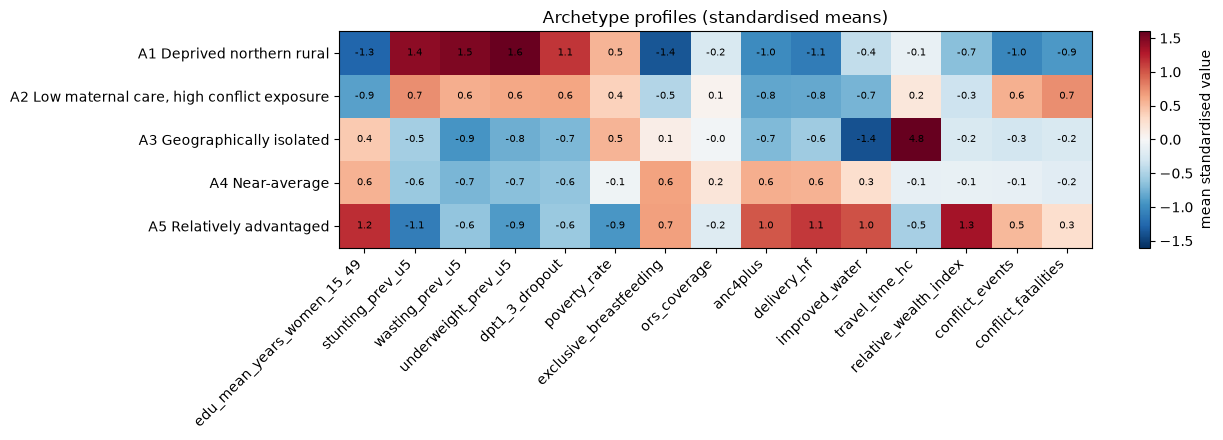

archetype_reproduced,1,2,3,4,5
edu_mean_years_women_15_49,2.49,3.67,7.42,7.85,9.65
stunting_prev_u5,57.29,46.94,27.91,27.23,19.65
wasting_prev_u5,13.77,11.22,6.94,7.54,7.81
underweight_prev_u5,39.12,28.94,14.13,15.40,12.93
dpt1_3_dropout,37.81,33.08,20.39,21.23,21.57
poverty_rate,42.66,39.34,42.62,31.13,15.04
exclusive_breastfeeding,8.39,16.78,22.06,26.99,27.14
ors_coverage,27.33,28.70,28.23,29.36,27.46
anc4plus,35.69,39.80,42.56,71.82,80.87
delivery_hf,9.76,19.22,26.82,60.68,77.79


In [5]:
prof = m.groupby("archetype_reproduced")[covs].mean()
zprof = pd.DataFrame(Xz, columns=covs).groupby(m.archetype_reproduced.values).mean()
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 4.5))
im = ax.imshow(zprof.values, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_yticks(range(5)); ax.set_yticklabels([f"A{k} {NAMES[k]}" for k in zprof.index])
ax.set_xticks(range(15)); ax.set_xticklabels(covs, rotation=45, ha="right")
for i in range(5):
    for j in range(15):
        ax.text(j, i, f"{zprof.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="mean standardised value"); ax.set_title("Archetype profiles (standardised means)"); plt.tight_layout(); plt.show()
prof.round(2).T

## 5. Robustness
* **Vaccination-related covariate.** One covariate (`dpt1_3_dropout`, IHME DPT1-to-DPT3 dropout, 2016) is a vaccination measure. Re-clustering without it shows how much the groups depend on it.
* **Alternative algorithm.** K-means with five groups on the same data.

In [6]:
from sklearn.cluster import KMeans
c14 = [c for c in covs if c != "dpt1_3_dropout"]
X14 = StandardScaler().fit_transform(X[c14])
lab14 = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X14)
labkm = KMeans(n_clusters=5, n_init=50, random_state=1).fit_predict(Xz)
print("ARI without the vaccination covariate:", round(adjusted_rand_score(m.archetype_reproduced, lab14), 3))
print("ARI Ward vs K-means (k = 5):", round(adjusted_rand_score(m.archetype_reproduced, labkm), 3))

ARI without the vaccination covariate: 0.452
ARI Ward vs K-means (k = 5): 0.472


## 6. Zero-dose burden by archetype (both methods)

In [7]:
d = m.merge(est, on="lga_uid", how="left", suffixes=("", "_e"))
tab = d.groupby(["archetype_reproduced", "archetype_name"]).agg(
    lgas=("lga_uid", "size"), children_12_23m=("cohort_12_23m", "sum"),
    method1_zero_dose=("method1_zero_dose_children", "sum"), method2_zero_dose=("method2_zero_dose_children", "sum"),
    method1_mean_rate=("method1_zero_dose_rate_pct", "mean"), method2_mean_rate=("method2_zero_dose_rate_pct", "mean"),
    anc4plus=("anc4plus", "mean"), facility_delivery=("delivery_hf", "mean"), travel_time=("travel_time_hc", "mean"),
    women_education_years=("edu_mean_years_women_15_49", "mean"), conflict_fatalities=("conflict_fatalities", "mean")).reset_index()
for c in ("children_12_23m", "method1_zero_dose", "method2_zero_dose"):
    tab[c + "_share_pct"] = tab[c] / tab[c].sum() * 100
v = d.dropna(subset=["anc4plus", "method1_zero_dose_rate_pct"])
print("Correlation of ANC4+ with the Method 1 LGA zero-dose rate:", round(np.corrcoef(v.anc4plus, v.method1_zero_dose_rate_pct)[0, 1], 2), f"(n = {len(v)})")
tab.round(1)

Correlation of ANC4+ with the Method 1 LGA zero-dose rate: -0.63 (n = 766)


,archetype_reproduced,archetype_name,lgas,children_12_23m,method1_zero_dose,method2_zero_dose,method1_mean_rate,method2_mean_rate,anc4plus,facility_delivery,travel_time,women_education_years,conflict_fatalities,children_12_23m_share_pct,method1_zero_dose_share_pct,method2_zero_dose_share_pct
0,1,Deprived northern rural,136,1508676.2,695337.0,773860.4,44.2,51.8,35.7,9.8,13.5,2.5,2.1,21.5,33.1,36.0
1,2,"Low maternal care, high conflict exposure",192,2090346.6,820871.0,890014.2,39.0,44.1,39.8,19.2,19.2,3.7,152.7,29.8,39.1,41.4
2,3,Geographically isolated,20,132758.9,23514.0,38593.9,17.7,29.0,42.6,26.8,107.8,7.4,11.8,1.9,1.1,1.8
3,4,Near-average,280,1903280.6,427791.0,349779.6,20.6,18.1,71.8,60.7,13.2,7.8,24.0,27.1,20.4,16.3
4,5,Relatively advantaged,146,1383644.7,131691.0,97313.4,9.9,7.4,80.9,77.8,5.5,9.6,24.5,19.7,6.3,4.5


## 7. Map

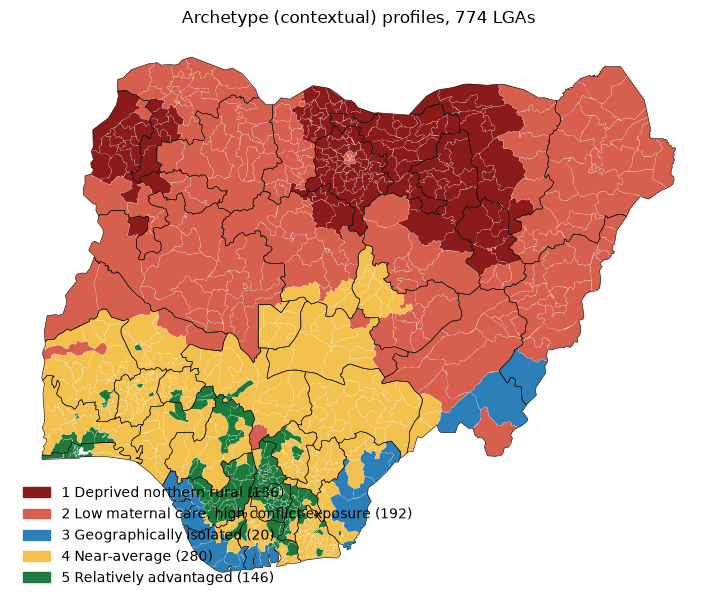

In [8]:
import geopandas as gpd
from matplotlib.patches import Patch
keys = pd.read_csv(DATA_DIR / "lga_map_keys_774.csv")
g = gpd.read_file(DATA_DIR / "nga_lgas.geojson").rename(columns={"lga_key": "geo_lga_key"}).drop(columns=["state", "lga"])
g = g.merge(keys[["lga_uid", "state_key", "geo_lga_key"]], on=["state_key", "geo_lga_key"]).merge(m[["lga_uid", "archetype_reproduced"]], on="lga_uid")
gs = gpd.read_file(DATA_DIR / "nga_states.geojson")
COL = {1: "#8B1A1A", 2: "#D6604D", 3: "#2C7FB8", 4: "#F2C14E", 5: "#1C7A3D"}
fig, ax = plt.subplots(figsize=(9, 8))
g.plot(ax=ax, color=g.archetype_reproduced.map(COL), edgecolor="white", linewidth=0.1)
gs.boundary.plot(ax=ax, color="black", linewidth=0.4); ax.axis("off")
ax.legend(handles=[Patch(color=COL[k], label=f"{k} {NAMES[k]} ({(m.archetype_reproduced == k).sum()})") for k in range(1, 6)], loc="lower left", frameon=False)
ax.set_title("Archetype (contextual) profiles, 774 LGAs"); plt.show()

## 8. Candidate intervention packages
| Archetype (contextual profile) | Defining barriers (measured) | Candidate package |
|---|---|---|
| 1 Deprived northern rural | highest child undernutrition, lowest maternal education and facility delivery, high DTP1-3 dropout | Reaching-Every-Community microplanning, BHCPF outreach and community health workers; co-deliver with nutrition and antenatal care; defaulter tracing |
| 2 Low maternal care, high conflict exposure | highest conflict events and fatalities, weak antenatal and delivery care | Security-integrated microplanning, negotiated access, mobile outreach teams and defaulter tracing |
| 3 Geographically isolated | very long travel time to care, low improved water | Outreach and mobile sessions (boat-based where waterways apply), community health worker networks, multi-antigen bundling per visit |
| 4 Near-average | near the national average on every indicator | Core fixed-site and outreach services, ward enumeration, Periodic Intensification of Routine Immunization |
| 5 Relatively advantaged | highest wealth, education and facility delivery; moderate conflict events | Targeted social mobilisation, fixed-plus-outreach hybrid, private-sector last-mile reach |

Population mobility, migration, riverine settlement and informal settlements are not measured by any input, so components that depend on them (for example transit-point vaccination) are not assigned; they need local confirmation first. In practice, each LGA's own flagged barriers (national top quartile of a domain score) should refine the package.

In [9]:
within = m.groupby("state").archetype_reproduced.nunique()
print("States containing 2 or more archetypes:", int((within >= 2).sum()), "| 3 or more:", int((within >= 3).sum()), "of", len(within))
m[["lga_uid", "zone", "state", "lga", "archetype_reproduced", "archetype_name"] + covs].to_csv(OUT_DIR / "lga_archetypes_774.csv", index=False)
tab.to_csv(OUT_DIR / "archetype_profiles_and_burden.csv", index=False)
print("Saved:", sorted(p.name for p in OUT_DIR.glob("*.csv")))

States containing 2 or more archetypes: 31 | 3 or more: 10 of 37
Saved: ['archetype_profiles_and_burden.csv', 'lga_archetypes_774.csv']


## Limitations
* The covariates are modelled surfaces (2016-2024) summarised to LGAs, not direct measurements.
* One covariate is vaccination-related (DPT dropout); results without it are shown above.
* Cluster boundaries are statistical; the archetype labels describe each group's measured profile. A given LGA may share features of more than one archetype (23% of LGAs are mixed between profiles).
* Matched packages are programme recommendations based on each profile; their effectiveness has not been evaluated here.